# SVM Practice Exercises
**From linear separation to margins, hinge loss, and kernel SVMs** — Wisconsin Diagnostic Breast Cancer (WDBC) subset

Features: mean **texture** and mean **smoothness**. Target: malignant (y = −1) or benign (y = +1).
This is for learning SVM concepts only, not a clinical model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Training data: 16 observations (texture, smoothness), y = -1 malignant, +1 benign
X_train = np.array([
    [19.83, 0.09342], [21.72, 0.09823], [20.20, 0.14470], [22.02, 0.09056],
    [17.35, 0.09446], [18.47, 0.11420], [25.27, 0.10820], [27.06, 0.10000],
    [16.02, 0.10880], [18.68, 0.09916], [20.97, 0.11020], [16.32, 0.11580],
    [12.74, 0.09311], [19.76, 0.08421], [17.18, 0.08045], [19.86, 0.10540]])
y_train = np.array([-1] * 8 + [1] * 8)

# Held-out test data: T1..T4
X_test = np.array([[17.89, 0.09710], [18.70, 0.11090], [21.01, 0.10440], [19.94, 0.10240]])
y_test = np.array([-1, -1, 1, 1])

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)

---
## Question 1 — Plot first: is a linear SVM suitable?
### (a) Scatter plot and one-line separation

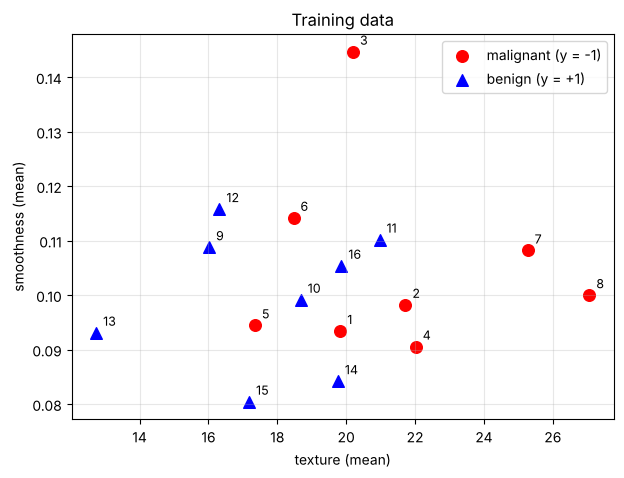

In [2]:
plt.figure(figsize=(7, 5))
plt.scatter(*X_train[y_train == -1].T, c="red", marker="o", s=70, label="malignant (y = -1)")
plt.scatter(*X_train[y_train == +1].T, c="blue", marker="^", s=70, label="benign (y = +1)")
for i, (t, s) in enumerate(X_train, start=1):          # write the observation number next to each point
    plt.annotate(str(i), (t, s), textcoords="offset points", xytext=(5, 5), fontsize=9)
plt.xlabel("texture (mean)")
plt.ylabel("smoothness (mean)")
plt.title("Training data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Answer (a).** **No — one straight line cannot separate all observations.** The two classes are mixed together in the plot:
- Malignant points 5 (17.35, 0.094) and 6 (18.47, 0.114) lie inside the region where the benign points 9, 10, 12 and 15 are.
- Benign points 11 (20.97, 0.110) and 16 (19.86, 0.105) lie among malignant points 1, 2 and 3.

So the classes overlap, and any straight line will leave some points on the wrong side. We can double-check this in the next cell: a linear SVM with a huge `C` (it tries very hard to avoid errors) still cannot reach 100 % training accuracy.

### (b) Standardization

In [3]:
scaler = StandardScaler().fit(X_train)       # mean and std are computed from the TRAINING data only
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)          # test data uses the same training mean/std

print("training mean (texture, smoothness):", scaler.mean_)
print("training std  (texture, smoothness):", scaler.scale_)
print("range of texture   :", X_train[:, 0].min(), "to", X_train[:, 0].max())
print("range of smoothness:", X_train[:, 1].min(), "to", X_train[:, 1].max())
print("after scaling -> mean:", X_train_s.mean(axis=0), " std:", X_train_s.std(axis=0))

# Check from (a): linear SVM with a very large C
hard = SVC(kernel="linear", C=1e6).fit(X_train_s, y_train)
print("training accuracy of linear SVM with C = 1e6:", hard.score(X_train_s, y_train))

training mean (texture, smoothness): [19.591  0.103]
training std  (texture, smoothness): [3.393 0.015]
range of texture   : 12.74 to 27.06
range of smoothness: 0.08045 to 0.1447
after scaling -> mean: [-0.  0.]  std: [1. 1.]
training accuracy of linear SVM with C = 1e6: 0.75


**Answer (b).** The two features have very different sizes: texture is about 13–27, smoothness is only about 0.08–0.145. An SVM works with distances and dot products, so the feature with the big numbers (texture) would dominate the margin and smoothness would be almost ignored. Standardizing (subtract mean, divide by std) puts both features on the same scale, so both can influence the boundary fairly. The scaler is fitted on the training set only, and the test set is transformed with the same numbers, so no test information leaks into training.

The last line confirms (a): even with `C = 1e6` the training accuracy is only 0.75, so the data are not linearly separable.

---
## Question 2 — Linear SVM: boundary, support lines, support vectors
From now on all plots use the **standardized** features.
### (a) Boundary, margin lines and support vectors

w = [-1.31  -0.191]   b = -0.218


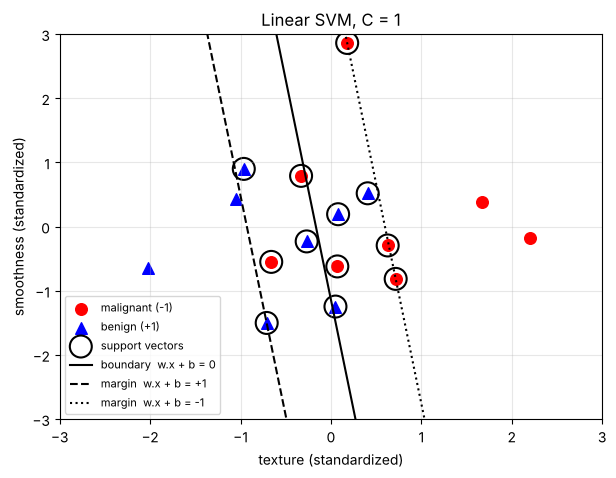

In [4]:
svm = SVC(kernel="linear", C=1).fit(X_train_s, y_train)
w = svm.coef_[0]            # weight vector
b = svm.intercept_[0]       # bias
print("w =", w, "  b =", round(b, 3))

x1 = np.linspace(-3, 3, 100)
def line(k):                # points where w.x + b = k  ->  x2 = (k - b - w1*x1) / w2
    return (k - b - w[0] * x1) / w[1]

plt.figure(figsize=(7, 5))
plt.scatter(*X_train_s[y_train == -1].T, c="red", marker="o", s=70, label="malignant (-1)")
plt.scatter(*X_train_s[y_train == +1].T, c="blue", marker="^", s=70, label="benign (+1)")
plt.scatter(*X_train_s[svm.support_].T, s=250, facecolors="none", edgecolors="black", linewidths=1.5, label="support vectors")
plt.plot(x1, line(0), "k-", label="boundary  w.x + b = 0")
plt.plot(x1, line(+1), "k--", label="margin  w.x + b = +1")
plt.plot(x1, line(-1), "k:", label="margin  w.x + b = -1")
plt.xlim(-3, 3); plt.ylim(-3, 3)
plt.xlabel("texture (standardized)"); plt.ylabel("smoothness (standardized)")
plt.title("Linear SVM, C = 1")
plt.legend(fontsize=8, loc="lower left"); plt.grid(alpha=0.3)
plt.show()

### (b) Number of support vectors and misclassifications

In [5]:
n_sv = len(svm.support_)
errors = (svm.predict(X_train_s) != y_train)
print("number of support vectors:", n_sv, "(per class:", svm.n_support_, ")")
print("support vector observations (No.):", svm.support_ + 1)
print("training misclassifications:", errors.sum(), "-> observations", np.where(errors)[0] + 1)
print("training accuracy:", round(svm.score(X_train_s, y_train), 3))

# Which points matter? Refit using ONLY the support vectors and compare w and b.
svm_sv = SVC(kernel="linear", C=1).fit(X_train_s[svm.support_], y_train[svm.support_])
print("w (all 16 points)    :", w, " b =", round(b, 3))
print("w (support vectors)  :", svm_sv.coef_[0], " b =", round(svm_sv.intercept_[0], 3))

number of support vectors: 12 (per class: [6 6] )
support vector observations (No.): [ 1  2  3  4  5  6 10 11 12 14 15 16]
training misclassifications: 5 -> observations [ 5  6 11 14 16]
training accuracy: 0.688
w (all 16 points)    : [-1.31  -0.191]  b = -0.218
w (support vectors)  : [-1.31  -0.191]  b = -0.218


**Answer (b).** The model has **12 support vectors** (6 per class) and **5 training misclassifications** (observations 5, 6, 11, 14, 16), so accuracy is 11/16 = 0.688.

The points that influence the boundary are the ones **on or inside the margin (and the misclassified ones)** — these are exactly the support vectors. Points far outside the margin have zero loss and do not change the boundary: when we refit using only the 12 support vectors we get the same `w` and `b`. Moving or removing a far-away point does nothing; moving a support vector changes the line.

### (c) Geometric margin width

In [6]:
margin_width = 2 / np.linalg.norm(w)
print("||w|| =", round(np.linalg.norm(w), 3))
print("margin width 2/||w|| =", round(margin_width, 3), "(in standardized units)")

||w|| = 1.323
margin width 2/||w|| = 1.511 (in standardized units)


**Answer (c).** The margin width is 2/‖w‖ = **1.511** (standardized units). SVM prefers a larger margin because a boundary with more empty space around it is less sensitive to small changes or noise in new data, so it usually generalizes better.

---
## Question 3 — Hinge loss: what happens inside the margin?
Score: f(xᵢ) = wᵀxᵢ + b. Hinge loss: ℓᵢ = max(0, 1 − yᵢ·f(xᵢ)).

In [7]:
f = svm.decision_function(X_train_s)            # f(x_i) for all training points
yf = y_train * f
hinge = np.maximum(0, 1 - yf)

def status(v):
    if v >= 0.995: return "correct, on/outside margin"   # yf = 1 means exactly on the margin line
    if v > 0:   return "correct, inside margin"
    return "misclassified"

table = pd.DataFrame({"No.": np.arange(1, 17), "y": y_train, "f(x)": f, "y*f(x)": yf,
                      "hinge loss": hinge, "status": [status(v) for v in yf]})
print(table.round(3).to_string(index=False))

print("\nThree chosen observations:")
chosen = table[table["No."].isin([7, 1, 5])]
print(chosen.round(3).to_string(index=False))
print("\nTotal hinge loss:", round(hinge.sum(), 3))

 No.  y   f(x)  y*f(x)  hinge loss                     status
   1 -1 -0.192   0.192       0.808     correct, inside margin
   2 -1 -0.983   0.983       0.017     correct, inside margin
   3 -1 -1.000   1.000       0.000 correct, on/outside margin
   4 -1 -1.000   1.000       0.000 correct, on/outside margin
   5 -1  0.752  -0.752       1.752              misclassified
   6 -1  0.064  -0.064       1.064              misclassified
   7 -1 -2.483   2.483       0.000 correct, on/outside margin
   8 -1 -3.067   3.067       0.000 correct, on/outside margin
   9  1  1.079   1.079       0.000 correct, on/outside margin
  10  1  0.178   0.178       0.822     correct, inside margin
  11  1 -0.849  -0.849       1.849              misclassified
  12  1  0.873   0.873       0.127     correct, inside margin
  13  1  2.549   2.549       0.000 correct, on/outside margin
  14  1 -0.045  -0.045       1.045              misclassified
  15  1  0.999   0.999       0.001 correct, on/outside margin
  16  1 

**Chosen observations** (values from the table above):

| Type | No. | yᵢ | f(xᵢ) | yᵢ·f(xᵢ) | ℓᵢ |
|---|---|---|---|---|---|
| (i) correct, outside the margin | 7 | −1 | −2.483 | 2.483 | 0.000 |
| (ii) correct, inside the margin | 1 | −1 | −0.192 | 0.192 | 0.808 |
| (iii) misclassified | 5 | −1 | 0.752 | −0.752 | 1.752 |

**Why can a correctly classified point still have positive hinge loss?** The hinge loss is zero only when yᵢ·f(xᵢ) ≥ 1, i.e. the point is on the correct side **and** outside the margin. Observation 1 is on the correct side (yᵢ·f = 0.192 > 0), but it is inside the margin (< 1), so its loss is 1 − 0.192 = 0.808. The loss "pushes" the boundary away from such points to keep a safe distance. For a misclassified point (yᵢ·f < 0) the loss is even bigger than 1.

---
## Question 4 — Kernel functions: can a curved boundary help?
We train four SVMs with `C = 1` on the same standardized data.

- Linear: K(x, z) = xᵀz
- Polynomial: K(x, z) = (xᵀz + 1)ᵖ with p = 2 and p = 3 → in scikit-learn: `kernel="poly", degree=p, gamma=1, coef0=1`
- RBF: K(x, z) = exp(−γ‖x − z‖²) with γ = 0.5 (this equals scikit-learn's default `gamma="scale"` for 2 standardized features)

Test points are drawn as **stars**.
### (a) Decision regions

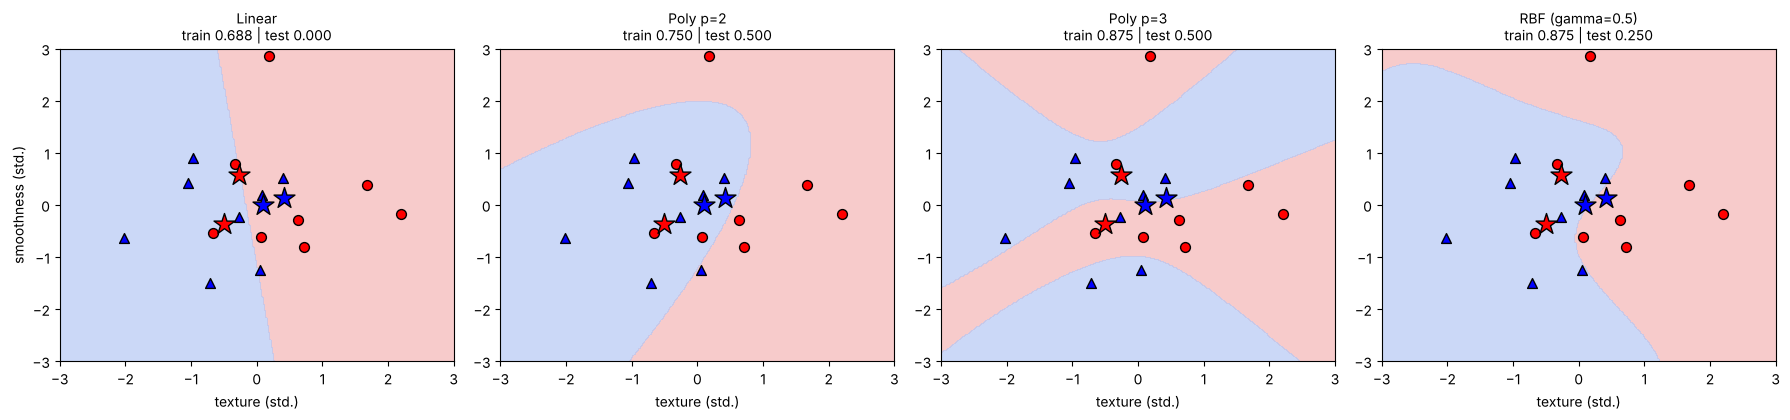

In [8]:
def plot_region(ax, model, title):
    g = np.linspace(-3, 3, 300)
    xx, yy = np.meshgrid(g, g)
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-2, 0, 2], colors=["#f4b6b6", "#b6c8f4"], alpha=0.7)   # red = malignant, blue = benign
    ax.scatter(*X_train_s[y_train == -1].T, c="red", marker="o", edgecolor="k", s=50)
    ax.scatter(*X_train_s[y_train == +1].T, c="blue", marker="^", edgecolor="k", s=50)
    ax.scatter(*X_test_s[y_test == -1].T, c="red", marker="*", edgecolor="k", s=250)
    ax.scatter(*X_test_s[y_test == +1].T, c="blue", marker="*", edgecolor="k", s=250)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)

models = {
    "Linear":        SVC(kernel="linear", C=1),
    "Poly p=2":      SVC(kernel="poly", degree=2, gamma=1, coef0=1, C=1),
    "Poly p=3":      SVC(kernel="poly", degree=3, gamma=1, coef0=1, C=1),
    "RBF (gamma=0.5)": SVC(kernel="rbf", gamma=0.5, C=1),
}
for m in models.values():
    m.fit(X_train_s, y_train)

# (b) numbers for the table
rows = []
for name, m in models.items():
    rows.append({"model": name,
                 "train acc": m.score(X_train_s, y_train),
                 "test acc": m.score(X_test_s, y_test),
                 "# support vectors": int(m.n_support_.sum()),
                 "test predictions (T1..T4)": list(m.predict(X_test_s))})

fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
for ax, (name, m), r in zip(axes, models.items(), rows):
    plot_region(ax, m, f"{name}\ntrain {r['train acc']:.3f} | test {r['test acc']:.3f}")
    ax.set_xlabel("texture (std.)")
axes[0].set_ylabel("smoothness (std.)")
plt.tight_layout()
plt.show()

**Answer (a).** The **linear** kernel gives a straight boundary. The **polynomial** (p = 2, 3) and **RBF** kernels give **curved (nonlinear)** boundaries. This matches Question 1: the classes were mixed — the benign points sit mostly in the left/middle part and the malignant points are on the right side and around them — so one straight line cannot split them, while a curved boundary can wrap around the benign group and fit the pattern better.

### (b) Training accuracy, test accuracy, number of support vectors

In [9]:
result = pd.DataFrame(rows)
print(result.to_string(index=False))
print("\ntrue test labels (T1..T4):", y_test.tolist())

          model  train acc  test acc  # support vectors test predictions (T1..T4)
         Linear      0.688      0.00                 12            [1, 1, -1, -1]
       Poly p=2      0.750      0.50                 12              [1, 1, 1, 1]
       Poly p=3      0.875      0.50                 11            [-1, 1, 1, -1]
RBF (gamma=0.5)      0.875      0.25                 16             [1, 1, -1, 1]

true test labels (T1..T4): [-1, -1, 1, 1]


**Answer (c).** I would select the **polynomial kernel with p = 3**.
- Linear is clearly the weakest: training accuracy 0.688 and **test accuracy 0.0** (all four test points wrong).
- Polynomial p = 3 has the best training accuracy (0.875, tied with RBF), the best test accuracy (0.50, tied with p = 2), and the fewest support vectors (11).
- Polynomial p = 2 has the same test accuracy but a lower training accuracy (0.750), and it predicts +1 for all test points.
- RBF (γ = 0.5) has the same training accuracy as p = 3 but a worse test accuracy (0.25) and uses all 16 points as support vectors.

The boundary of p = 3 is curved but still smooth, so the complexity is moderate. **Warning:** there are only 4 test points, so this choice is weak evidence — every test accuracy here is one of 0, 0.25, 0.5 … and none of the models is really good.

---
## Question 5 — Understanding C and γ in the RBF SVM
We try all combinations C ∈ {0.1, 1, 100} and γ ∈ {0.1, 1, 10}. Stars are test points.

    C  gamma  train acc  test acc  # support vectors
  0.1    0.1      0.750      0.25                 16
  0.1    1.0      0.875      0.50                 16
  0.1   10.0      1.000      1.00                 16
  1.0    0.1      0.750      0.25                 14
  1.0    1.0      0.875      0.50                 16
  1.0   10.0      1.000      1.00                 16
100.0    0.1      0.812      0.50                 14
100.0    1.0      1.000      0.50                 13
100.0   10.0      1.000      1.00                 16


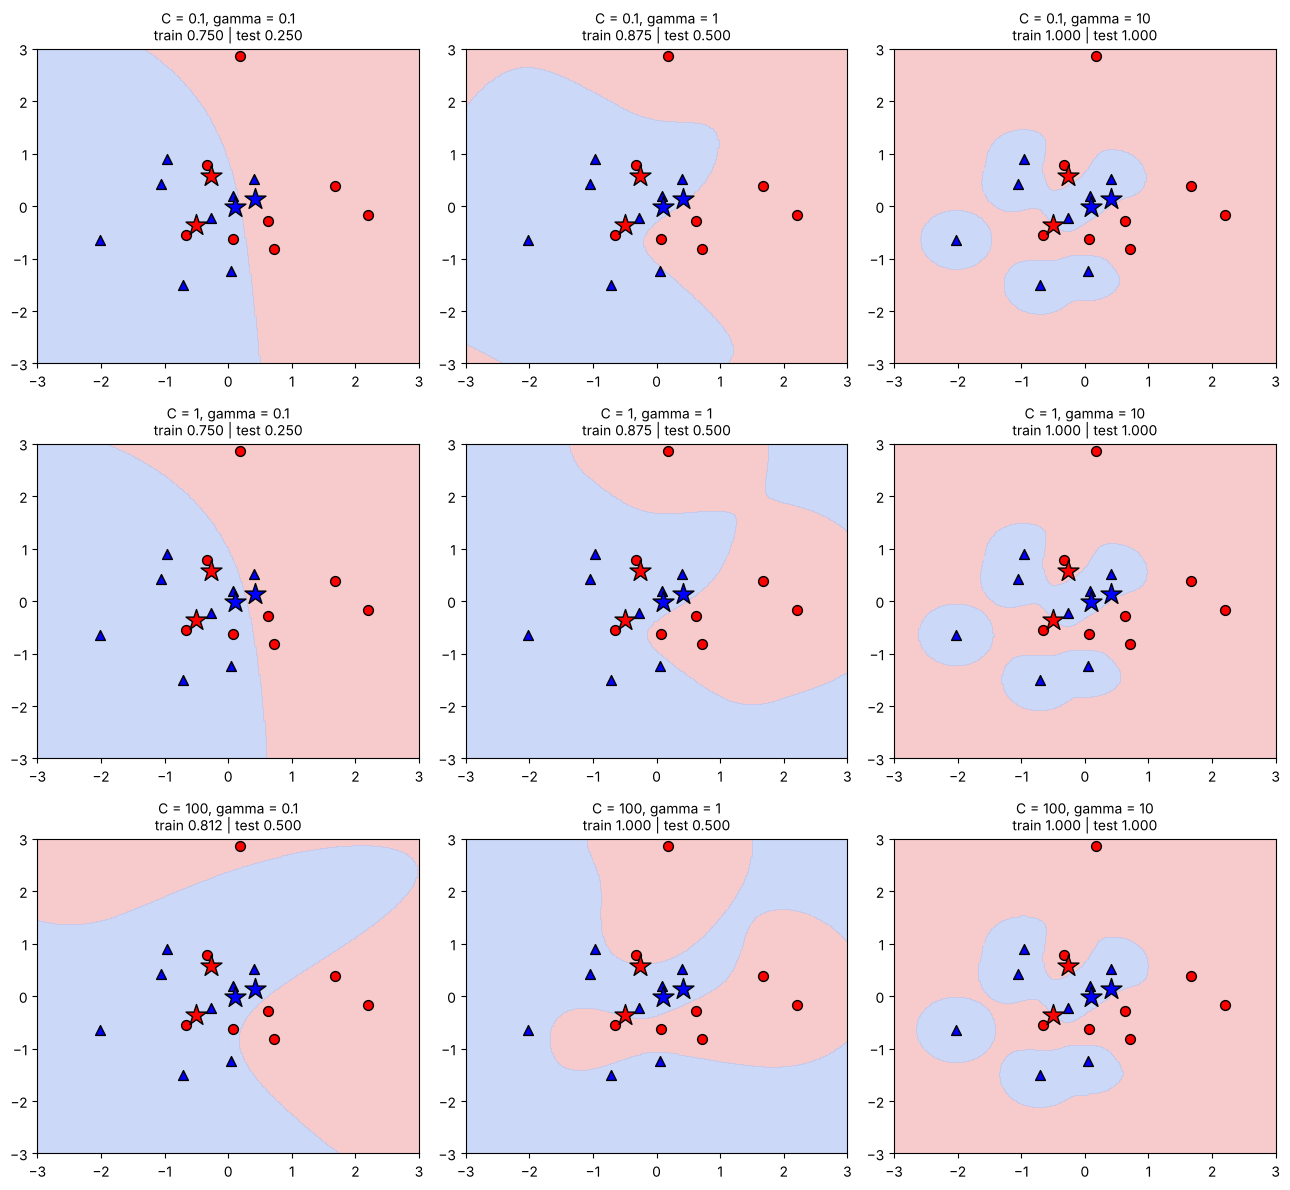

In [10]:
Cs = [0.1, 1, 100]
gammas = [0.1, 1, 10]
grid_rows = []

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for i, C in enumerate(Cs):
    for j, g in enumerate(gammas):
        m = SVC(kernel="rbf", C=C, gamma=g).fit(X_train_s, y_train)
        tr, te = m.score(X_train_s, y_train), m.score(X_test_s, y_test)
        grid_rows.append({"C": C, "gamma": g, "train acc": tr, "test acc": te, "# support vectors": int(m.n_support_.sum())})
        plot_region(axes[i, j], m, f"C = {C}, gamma = {g}\ntrain {tr:.3f} | test {te:.3f}")
plt.tight_layout()
plt.show()

print(pd.DataFrame(grid_rows).to_string(index=False))

### (a) Underfitting and overfitting
- **Underfit: C = 0.1, γ = 0.1.** The boundary is almost a straight, very smooth line, the training accuracy is only 0.750 and the test accuracy is 0.250. The model is too simple/too soft to follow the pattern. (C = 1, γ = 0.1 looks the same.)
- **Overly complex / likely overfit: C = 100, γ = 1.** The boundary becomes wiggly and bends around single points to reach training accuracy 1.000, but the test accuracy is only 0.500 — a big gap between training and test performance. (With γ = 10 the boundary is also complex: small separate "islands" around single benign points.)

### (b) What C and γ change
- **Increasing C** makes errors and margin violations more expensive. The margin gets narrower and the boundary tries harder to classify every training point correctly, so it becomes more complex. Small C = wide, soft margin that tolerates mistakes.
- **Increasing γ** makes the RBF kernel "narrower": each training point influences only its close neighbourhood. The boundary becomes more local and wiggly (islands around points). Small γ = every point influences far away, so the boundary is smooth and close to linear.

### (c) Final choice: **C = 1, γ = 10**
- It reaches training accuracy 1.000 **and test accuracy 1.000** (all four test points are correct). All γ = 1 and γ = 0.1 settings get at most 0.500 on the test set, so a large γ is needed here: the benign points form small local groups and a small γ is too smooth to capture them.
- Among the γ = 10 settings, C does not change the result (all three have train = test = 1.000 and a similar boundary), so I take the middle value C = 1, which keeps the margin softer than C = 100.
- **Caveat:** the boundary for γ = 10 consists of small islands around the benign training points, which is a sign of high complexity, and the test set has only 4 points, so the 100 % may be partly luck. With more data I would confirm this choice with cross-validation.